# Q5 experiment — Small U-Net CNN

**Experimental notebook; classical solution remains unchanged.** The user explicitly authorized this neural-network experiment. Train separate small in-vivo/ex-vivo U-Nets **from scratch**, using only released training images and masks. No pretrained weights or external data.

Use two mice (29 regions) for training and the third (`subject_db6b8b`, 18 regions) for evaluation. These mice were already inspected in earlier classical experiments, so this is a grouped **development comparison**, not a fresh untouched test. Training lasts a fixed 12 epochs per modality; evaluation labels do not select weights, thresholds or epochs. No Kaggle upload is performed.

Architecture follows the contracting/expanding paths and skip connections of [Ronneberger et al., U-Net](https://arxiv.org/abs/1505.04597), reduced to two pooling levels and 16/32/64 channels. Lecture 6 motivates separate modality models, cell/background patch sampling, augmentation and Dice loss. [PyTorch BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html) provides stable binary cross-entropy; [MPS](https://docs.pytorch.org/docs/stable/notes/mps.html) enables Apple GPU execution.

Install the optional dependency with `.venv/bin/python -m pip install -r requirements-unet.txt`. All architecture/training code is below. Reuse only loading, RLE, metric and classical registration/matching helpers from `cell_matching.py`.

In [1]:
from pathlib import Path
import json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2, tifffile, torch
from torch import nn
from torch.nn import functional as F
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries, watershed, relabel_sequential, mark_boundaries
from skimage.feature import peak_local_max
from cell_matching import (normalize, mask_quality, register, match_cells, evaluate, summarize,
                           read_pair, decode_rle, PARAMETERS)

SEED, EPOCHS, STEPS, BATCH, PATCH = 7, 12, 60, 8, 128
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
root, out = Path("Data"), Path("outputs/q5/unet")
out.mkdir(parents=True, exist_ok=True)
rows = pd.read_csv(root / "training/train_ground_truth.csv")
evaluation = rows.sample_id.str.split("__").str[0] == "subject_db6b8b"
training_rows, evaluation_rows = rows[~evaluation], rows[evaluation]
assert set(training_rows.sample_id.str.split("__").str[0]).isdisjoint(evaluation_rows.sample_id.str.split("__").str[0])
print(torch.__version__, device, f"{len(training_rows)} training / {len(evaluation_rows)} evaluation regions")

2.14.1 mps 29 training / 18 evaluation regions


## 1. Supervision and patch sampling

Preserve original 16-bit images and normalize derived processing arrays. Decode instance masks into foreground and eroded-interior targets; the second channel helps keep touching cells separate. Sample 60% of patch centers from annotated cells, 20% from bright non-cell pixels and 20% uniformly. Bright-background sampling targets fibers and neuropil; it is not iterative model-mined hard-negative training. Rotate/flip image and targets together, then perturb image brightness/gamma/noise only.

In [2]:
def load_record(row, modality):
    image = normalize(tifffile.imread(root / "training" / Path(*row.sample_id.split("__")) / f"{modality}.tif"))
    labels = np.zeros(image.shape, np.int32)
    centers, areas = [], []
    for i, rle in enumerate(json.loads(getattr(row, modality + "_instances")).values(), 1):
        runs = np.array(rle.split(), int).reshape(-1, 2)
        pixels = np.concatenate([np.arange(s, s+n) for s, n in runs])
        labels.ravel()[pixels] = i
        centers.append([np.mean(pixels // image.shape[1]), np.mean(pixels % image.shape[1])])
        areas.append(len(pixels))
    foreground = labels > 0
    core = ndi.binary_erosion(foreground & ~find_boundaries(labels, mode="inner"))
    targets = np.stack([foreground, core]).astype(np.float32)
    background = np.argwhere((image > np.percentile(image, 90)) & ~ndi.binary_dilation(foreground, iterations=3))
    assert min(image.shape) >= PATCH
    return image, targets, np.array(centers), background, np.array(areas)


def sample_batch(records, rng):
    xs, ys = [], []
    for _ in range(BATCH):
        image, targets, centers, background, _ = records[rng.integers(len(records))]
        h, w = image.shape
        choice = rng.random()
        points = centers if choice < .6 else background if choice < .8 else []
        y, x = points[rng.integers(len(points))] if len(points) else [rng.integers(h), rng.integers(w)]
        y, x = int(np.clip(y-PATCH//2, 0, h-PATCH)), int(np.clip(x-PATCH//2, 0, w-PATCH))
        a, b = image[y:y+PATCH, x:x+PATCH], targets[:, y:y+PATCH, x:x+PATCH]
        k = rng.integers(4)
        a, b = np.rot90(a, k), np.rot90(b, k, axes=(-2, -1))
        if rng.random() < .5:
            a, b = a[:, ::-1], b[:, :, ::-1]
        a = np.clip(a ** rng.uniform(.8, 1.2) * rng.uniform(.85, 1.15) + rng.normal(0, .01, a.shape), 0, 1)
        xs.append(a[None].astype(np.float32))
        ys.append(b.copy())
    return torch.from_numpy(np.stack(xs)).to(device), torch.from_numpy(np.stack(ys)).to(device)

## 2. Two-level U-Net

Two 3×3 convolutions per block, GroupNorm/ReLU, max pooling and bilinear upsampling with concatenated skip features. Two logits predict foreground and cell interiors. Optimize binary cross-entropy plus soft Dice across both channels. This is a small adaptation, not the original full-size U-Net.

In [3]:
def block(inputs, outputs):
    return nn.Sequential(nn.Conv2d(inputs, outputs, 3, padding=1), nn.GroupNorm(4, outputs), nn.ReLU(),
                         nn.Conv2d(outputs, outputs, 3, padding=1), nn.GroupNorm(4, outputs), nn.ReLU())


class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1, self.enc2, self.bottom = block(1, 16), block(16, 32), block(32, 64)
        self.dec2, self.dec1 = block(96, 32), block(48, 16)
        self.head = nn.Conv2d(16, 2, 1)

    def forward(self, x):
        a = self.enc1(x)
        b = self.enc2(F.max_pool2d(a, 2))
        c = self.bottom(F.max_pool2d(b, 2))
        d = self.dec2(torch.cat([F.interpolate(c, size=b.shape[-2:], mode="bilinear", align_corners=False), b], 1))
        d = self.dec1(torch.cat([F.interpolate(d, size=a.shape[-2:], mode="bilinear", align_corners=False), a], 1))
        return self.head(d)


def loss_function(logits, targets):
    probabilities = logits.sigmoid()
    intersection = (probabilities * targets).sum((0, 2, 3))
    dice = (2 * intersection + 1) / (probabilities.sum((0, 2, 3)) + targets.sum((0, 2, 3)) + 1)
    return F.binary_cross_entropy_with_logits(logits, targets) + (1 - dice).mean()


print(f"Parameters per model: {sum(p.numel() for p in SmallUNet().parameters()):,}")
probe = SmallUNet().to(device)
x = torch.randn(2, 1, PATCH, PATCH, device=device)
assert probe(x).shape == (2, 2, PATCH, PATCH)
loss_function(probe(x), torch.zeros(2, 2, PATCH, PATCH, device=device)).backward()
assert all(torch.isfinite(p.grad).all() for p in probe.parameters() if p.grad is not None)
del probe, x
print("Forward/backward shape and finite-gradient checks passed")

Parameters per model: 118,642


Forward/backward shape and finite-gradient checks passed


## 3. Train from scratch

AdamW with a cosine learning-rate schedule; fixed training budget, no evaluation-based checkpoint selection. Save final state dictionaries and the actual mouse split. Rerunning this cell retrains and replaces only this experiment's checkpoints. Seeds improve repeatability; GPU training can still vary slightly between runs.

invivo epoch 1/12: loss=1.0812


invivo epoch 2/12: loss=0.8315


invivo epoch 3/12: loss=0.6551


invivo epoch 4/12: loss=0.5157


invivo epoch 5/12: loss=0.4179


...

exvivo epoch 8/12: loss=0.5053


exvivo epoch 9/12: loss=0.4645


exvivo epoch 10/12: loss=0.4528


exvivo epoch 11/12: loss=0.4296


exvivo epoch 12/12: loss=0.4215


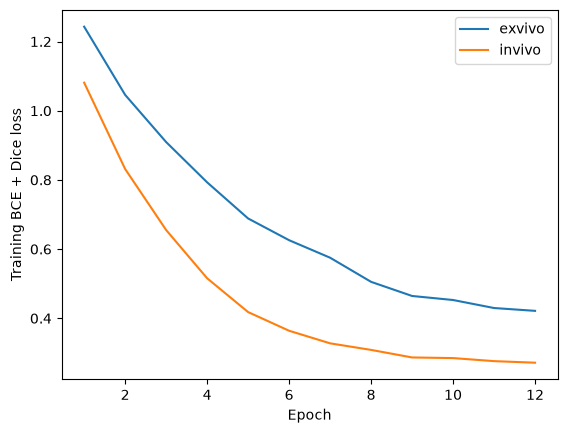

In [4]:
models, area_limits, history = {}, {}, []
for modality in ["invivo", "exvivo"]:
    records = [load_record(row, modality) for row in training_rows.itertuples(index=False)]
    areas = np.concatenate([record[-1] for record in records])
    area_limits[modality] = [max(5, int(np.quantile(areas, .005))), int(np.quantile(areas, .995))]
    torch.manual_seed(SEED)
    rng = np.random.default_rng(SEED)
    model = SmallUNet().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS, eta_min=1e-4)
    start = time.time()
    for epoch in range(EPOCHS):
        model.train()
        losses = []
        for _ in range(STEPS):
            x, y = sample_batch(records, rng)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_function(model(x), y)
            assert torch.isfinite(loss)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        scheduler.step()
        history.append(dict(modality=modality, epoch=epoch+1, loss=float(np.mean(losses)), seconds=time.time()-start))
        pd.DataFrame(history).to_csv(out / "training_history.csv", index=False)
        print(f"{modality} epoch {epoch+1}/{EPOCHS}: loss={np.mean(losses):.4f}")
    models[modality] = model.eval()
    torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, out / f"{modality}.pt")
    del records, optimizer
metadata = dict(seed=SEED, epochs=EPOCHS, steps=STEPS, batch=BATCH, patch=PATCH,
                torch_version=torch.__version__, device=str(device), area_limits=area_limits,
                training_ids=training_rows.sample_id.tolist(), evaluation_ids=evaluation_rows.sample_id.tolist())
(out / "experiment.json").write_text(json.dumps(metadata, indent=2))
for modality, group in pd.DataFrame(history).groupby("modality"):
    plt.plot(group.epoch, group.loss, label=modality)
plt.xlabel("Epoch"); plt.ylabel("Training BCE + Dice loss"); plt.legend(); plt.show()

## 4. Native-resolution instance masks

Predict overlapping 256-pixel tiles and average their probabilities, retaining native image dimensions. Threshold foreground/interiors at 0.5; interior maxima seed watershed on foreground distance. Filter instance areas using only training-mask quantiles. These fixed thresholds are not tuned on the evaluation mouse. Missing cores yield missed cells, and erroneous cores can split cells.

In [5]:
@torch.inference_mode()
def probabilities(image, model, tile=256, stride=192):
    image = normalize(image)
    h, w = image.shape
    padded = np.pad(image, ((0, max(0, tile-h)), (0, max(0, tile-w))), mode="reflect")
    ph, pw = padded.shape
    ys = sorted(set(list(range(0, ph-tile+1, stride)) + [ph-tile]))
    xs = sorted(set(list(range(0, pw-tile+1, stride)) + [pw-tile]))
    positions = [(y, x) for y in ys for x in xs]
    result, count = np.zeros((2, ph, pw), np.float32), np.zeros((ph, pw), np.float32)
    model.eval()
    for start in range(0, len(positions), BATCH):
        batch = positions[start:start+BATCH]
        patches = np.stack([padded[y:y+tile, x:x+tile] for y, x in batch])[:, None]
        values = model(torch.from_numpy(patches).to(device)).sigmoid().cpu().numpy()
        for (y, x), value in zip(batch, values):
            result[:, y:y+tile, x:x+tile] += value
            count[y:y+tile, x:x+tile] += 1
    assert (count > 0).all()
    return (result / count)[:, :h, :w]


def instances_from_probabilities(probability, limits):
    foreground = ndi.binary_fill_holes(probability[0] > .5)
    distance = ndi.distance_transform_edt(foreground)
    peaks = peak_local_max(ndi.gaussian_filter(probability[1], .7), min_distance=3,
                           threshold_abs=.5, labels=foreground.astype(np.uint8), exclude_border=False)
    markers = np.zeros(foreground.shape, np.int32)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks)+1)
    labels = watershed(-distance, markers, mask=foreground)
    areas = np.bincount(labels.ravel())
    keep = (areas >= limits[0]) & (areas <= limits[1])
    keep[0] = False
    labels[~keep[labels]] = 0
    return relabel_sequential(labels)[0].astype(np.int32)

## 5. Evaluate against the classical solution on the same mouse

Use the unchanged classical affine registration and Hungarian matching, replacing only the instance masks with U-Net predictions. Report modality PQ, pooled matching F1 and combined score at strict IoU >0.75. This isolates a segmentation experiment; improving masks does not automatically fix alignment. Compare against the current classical pipeline using its fixed final gate/cutoff, not a different cross-validation fold's settings.

In [6]:
from cell_matching import predict_pair
records, baseline_records = [], []
for row in evaluation_rows.itertuples(index=False):
    images = read_pair(root / "training", row.sample_id)
    prediction = []
    for modality, image in zip(["invivo", "exvivo"], images):
        probability = probabilities(image, models[modality])
        prediction.append(instances_from_probabilities(probability, area_limits[modality]))
    matrix, confidence = register(*images)
    pairs, _ = match_cells(*prediction, matrix, PARAMETERS["matching"]["gate"]) if confidence >= PARAMETERS["matching"]["cutoff"] else ([], matrix)
    records.append(dict(sample_id=row.sample_id, **evaluate(prediction, pairs, row)))
    baseline, baseline_pairs, _, _ = predict_pair(images)
    baseline_records.append(dict(sample_id=row.sample_id, **evaluate(baseline, baseline_pairs, row)))
    pd.DataFrame(records).to_csv(out / "evaluation_per_region.csv", index=False)
    print(row.sample_id, [int(mask.max()) for mask in prediction], len(pairs))
results = pd.DataFrame({"Classical (same 18 regions)": summarize(pd.DataFrame(baseline_records)),
                        "Small U-Net experiment": summarize(pd.DataFrame(records))}).T
results.to_csv(out / "comparison.csv")
pd.DataFrame(baseline_records).to_csv(out / "classical_per_region.csv", index=False)
display(results.round(4))

subject_db6b8b__region_067f7e [456, 220] 0


subject_db6b8b__region_148132 [436, 109] 0


subject_db6b8b__region_1b72a7 [458, 192] 0


subject_db6b8b__region_261dc0 [456, 176] 37


subject_db6b8b__region_2e6e9e [429, 90] 0


...

subject_db6b8b__region_b7618f [456, 135] 0


subject_db6b8b__region_ce8b99 [456, 217] 0


subject_db6b8b__region_f6d150 [455, 226] 69


subject_db6b8b__region_fe3e4d [456, 165] 0


,pq_invivo,pq_exvivo,f1_match,score
Classical (same 18 regions),0.4119,0.2337,0.0607,0.1918
Small U-Net experiment,0.4757,0.3064,0.1164,0.2537


## 6. Inspect predictions and checkpoints

Display the first evaluation region in dataset order. Crops are centered automatically on annotated cells for visualization only; annotations never initialize predictions. Save native-size labels and inspect probability maps, instance boundaries and known masks.

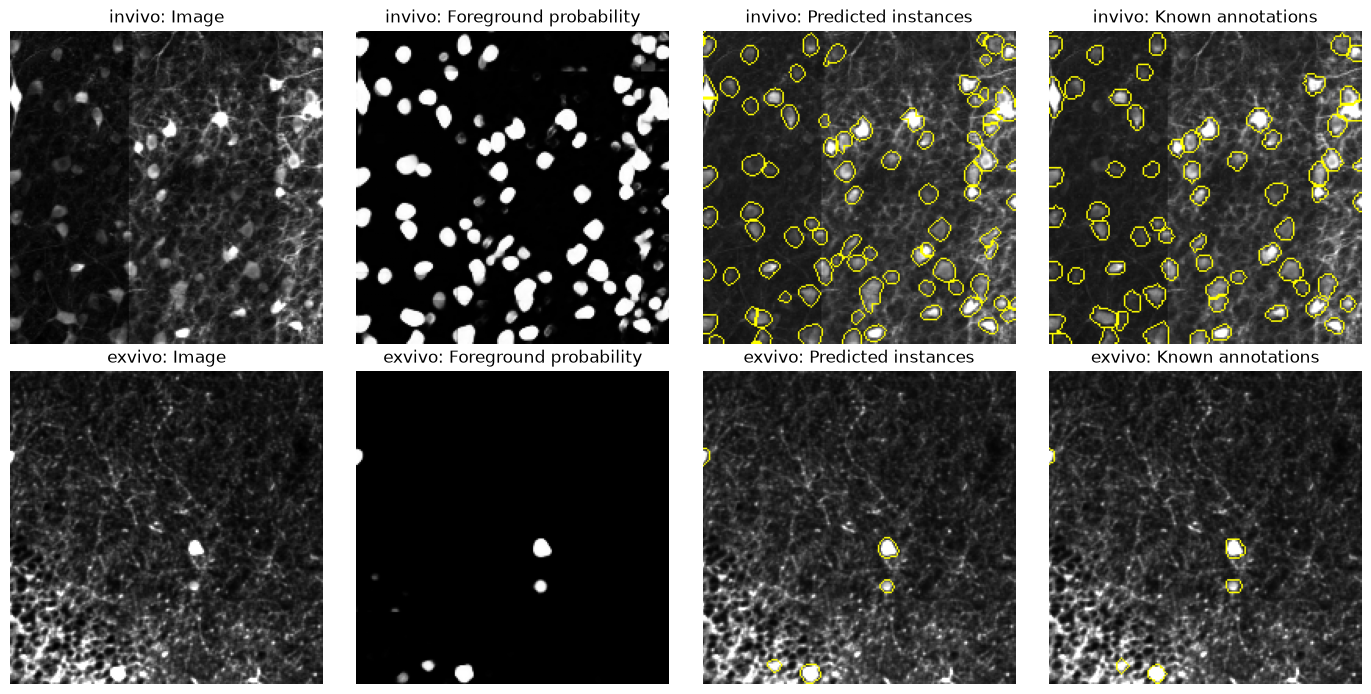

Native-size outputs and checkpoint reload checks passed


In [7]:
example = next(evaluation_rows.itertuples(index=False))
images = read_pair(root / "training", example.sample_id)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, (modality, image) in enumerate(zip(["invivo", "exvivo"], images)):
    probability = probabilities(image, models[modality])
    labels = instances_from_probabilities(probability, area_limits[modality])
    truth = np.zeros(image.shape, np.int32)
    for label, rle in enumerate(json.loads(getattr(example, modality + "_instances")).values(), 1):
        truth[decode_rle(rle, image.shape)] = label
    y, x = np.median(np.argwhere(truth > 0), axis=0).astype(int)
    crop = np.s_[max(0, y-100):y+100, max(0, x-100):x+100]
    shown = [normalize(image)[crop], probability[0][crop],
             mark_boundaries(normalize(image)[crop], labels[crop]), mark_boundaries(normalize(image)[crop], truth[crop])]
    for ax, picture, title in zip(axes[i], shown, ["Image", "Foreground probability", "Predicted instances", "Known annotations"]):
        ax.imshow(picture, cmap="gray"); ax.set_title(f"{modality}: {title}"); ax.axis("off")
    tifffile.imwrite(out / f"example_{modality}_labels.tif", labels.astype(np.uint16))
    reloaded = SmallUNet().to(device)
    reloaded.load_state_dict(torch.load(out / f"{modality}.pt", map_location="cpu", weights_only=True))
    reloaded.eval()
    patch = torch.from_numpy(normalize(image)[:128, :128][None, None]).to(device)
    with torch.inference_mode():
        torch.testing.assert_close(models[modality](patch), reloaded(patch))
plt.tight_layout(); plt.savefig(out / "predictions.png", dpi=150); plt.show()
print("Native-size outputs and checkpoint reload checks passed")

## Interpretation and reproducibility

Report the measured comparison above, not the 0.70 target. This limited experiment trains small models from scratch; model capacity, annotation style, domain shift and the unchanged registration can limit performance. Evaluation labels did not select CNN weights or postprocessing thresholds, but the same data was previously inspected during classical development. No new independent test or leaderboard score is claimed.

Artifacts stay in `outputs/q5/unet/`: two checkpoints, split/hyperparameter metadata, training history, per-region metrics, comparison and figures. The classical notebook, code, candidate CSVs, Q1–Q4 and README are preserved. This experiment does not retrain on all mice, generate a hidden-test submission or upload to Kaggle.

## AI assistance

OpenAI Codex assisted with this authorized CNN experiment. See `AI_USAGE.md` for the actual prompt sequence.